# Autoencoder + Isolation Forest
### IoMT Anomaly Detection | Reproducible experiment

**Research question:** Does Isolation Forest on the autoencoder's latent representation detect attacks better than reconstruction error?

**Protocol:** Train on benign `X_train`, use benign `X_val` for validation/threshold calibration, and use `X_test` **only once for final reporting**. No resplitting or rescaling. Seed = 42. The PCA reference F1 is **0.761**.

**Run:** Runtime → Run all in Google Colab. This notebook downloads the team's repository; an internet connection is required. Results are not precomputed. Change only the **CONFIG** cell to run a new, *preplanned* experiment. Do not choose hyperparameters using test results.

## 1 — Setup & dataset

In [ ]:
import os, sys, json, subprocess, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers, regularizers
from sklearn.ensemble import IsolationForest
import joblib

REPO = Path('/content/iomt-anomaly-detection')
if not REPO.exists():
    subprocess.run(['git', 'clone', 'https://github.com/JanaAlzobidi/iomt-anomaly-detection.git', str(REPO)], check=True)
sys.path.insert(0, str(REPO))
from evaluate import load_data, evaluate, reconstruction_errors, per_feature_errors
DATA_DIR = str(REPO / 'data')
RESULTS_DIR = str(REPO / 'results')
os.makedirs(RESULTS_DIR, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
X_train, X_val, X_test, y_test, attack_test = load_data(DATA_DIR)
print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1] == 40

X_train (150000, 40) (benign only) | X_val (30000, 40) (benign only) | X_test (42893, 40), attacks: 5286 (12.3%)
Train: (150000, 40) | Val: (30000, 40) | Test: (42893, 40)


## 2 — CONFIG


In [ ]:
# A pre-specified configuration — do not adjust based on test F1
EXPERIMENT = 'latent16_linear_l2'
LATENT_SIZE = 16           # Preplanned alternatives: 8, 16, 32
LATENT_ACTIVATION = 'linear'  # Compare with 'relu' in a separate run
L2_STRENGTH = 1e-5        # Compare with 0 in a separate run
LEARNING_RATE = 1e-3
EPOCHS = 40
BATCH_SIZE = 256
N_ESTIMATORS = 200
MAX_SAMPLES = 512
THRESHOLD_PERCENTILE = 99  # Calibrated using benign validation ONLY

## 3 — Build & train Autoencoder
The encoder compresses 40 features to a latent representation; the decoder reconstructs 40 values. Both input and target are `X_train` because this is unsupervised reconstruction training.

Model: "ae_isoforest"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 40)             │         1,320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,032 (19.66 KB)

 Trainable params: 5,032 (19.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.0152 - val_loss: 0.0022
Epoch 2/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0018 - val_loss: 0.0015
Epoch 3/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0013 - val_loss: 0.0012
Epoch 4/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0011 - val_loss: 0.0010
Epoch 5/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 9.9097e-04 - val_loss: 9.4705e-04
Epoch 6/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 9.1450e-04 - val_loss: 8.7929e-04
Epoch 7/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 8.5253e-04 - val_loss: 8.2175e-04
Epoch 8/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 7.9920e-04 - val_loss: 7.7160e-04
Epoch 9/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 7.5241e-04 - val_loss: 7.3240e-04
Epoch 10/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 7.1484e-04 - val_loss: 6.9907e-04
Epoch 11/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 6.8321e-04 - val_loss: 6.704

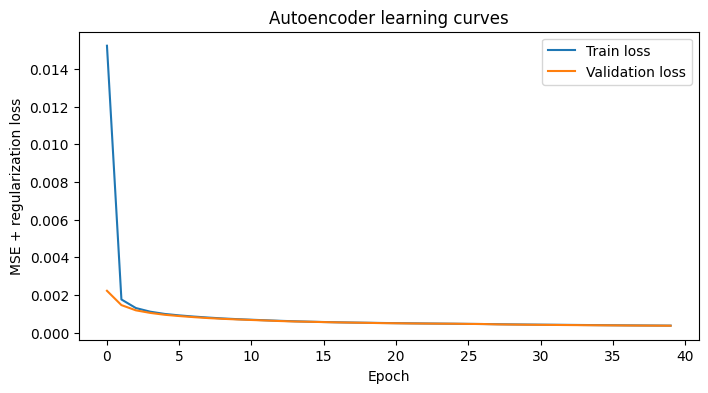

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(40,), name='input')
x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(L2_STRENGTH))(inputs)
x = layers.Dense(24, activation='relu', kernel_regularizer=regularizers.l2(L2_STRENGTH))(x)
latent = layers.Dense(LATENT_SIZE, activation=LATENT_ACTIVATION, name='latent')(x)
x = layers.Dense(24, activation='relu', kernel_regularizer=regularizers.l2(L2_STRENGTH))(latent)
x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(L2_STRENGTH))(x)
outputs = layers.Dense(40, activation='linear', name='reconstruction')(x)
autoencoder = keras.Model(inputs, outputs, name='ae_isoforest')
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='mse')
autoencoder.summary()
history = autoencoder.fit(X_train, X_train, validation_data=(X_val, X_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=1,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)])
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('MSE + regularization loss'); plt.title('Autoencoder learning curves')
plt.legend(); plt.show()

## 4 — Inspect latent features
A nearly constant feature provides little variation to Isolation Forest. `zero_pct` is especially informative for ReLU; with linear activation it may naturally be close to zero.

In [ ]:
encoder = keras.Model(autoencoder.inputs, autoencoder.get_layer('latent').output)
Z_train = encoder.predict(X_train, verbose=0)
Z_val = encoder.predict(X_val, verbose=0)
latent_stats = pd.DataFrame({'latent_feature': np.arange(1, LATENT_SIZE+1),
    'mean': Z_train.mean(axis=0), 'std': Z_train.std(axis=0),
    'zero_pct': 100 * np.mean(np.isclose(Z_train, 0, atol=1e-8), axis=0)})
display(latent_stats.round(4))
print('Near-constant features:', int((latent_stats['std'] < 1e-6).sum()))

,latent_feature,mean,std,zero_pct
0,1,-0.9625,0.1934,0.0
1,2,-0.2532,0.2345,0.0
2,3,0.8019,0.2315,0.0
3,4,-1.3285,0.3086,0.0
4,5,0.2138,0.1658,0.0
5,6,0.2521,0.5139,0.0
6,7,0.1066,0.3619,0.0
7,8,-0.4424,0.1842,0.0
8,9,0.1863,0.2628,0.0
9,10,-1.0163,0.4950,0.0


Near-constant features: 0


## 5 — Train Isolation Forest on benign latent vectors
`score_samples()` is smaller for more unusual observations, so negate it to make **higher = more anomalous**. `contamination` is intentionally not used to set the final decision threshold.

Validation-calibrated threshold: 0.632709
Train flagged %: 1.072
Validation flagged %: 1.0


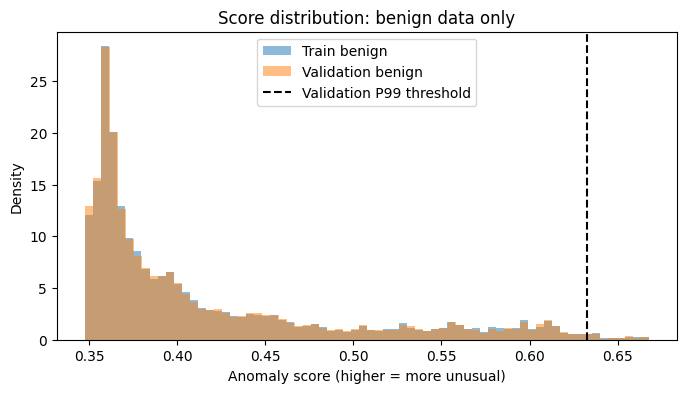

In [ ]:
iso = IsolationForest(n_estimators=N_ESTIMATORS, max_samples=MAX_SAMPLES,
                      random_state=SEED, n_jobs=-1)
iso.fit(Z_train)
def iso_scores(X):
    z = encoder.predict(np.asarray(X), verbose=0)
    return -iso.score_samples(z)
train_scores = -iso.score_samples(Z_train)
val_scores = -iso.score_samples(Z_val)
threshold = float(np.percentile(val_scores, THRESHOLD_PERCENTILE))
print('Validation-calibrated threshold:', round(threshold, 6))
print('Train flagged %:', round(100 * np.mean(train_scores > threshold), 3))
print('Validation flagged %:', round(100 * np.mean(val_scores > threshold), 3))
plt.figure(figsize=(8,4))
plt.hist(train_scores, bins=70, alpha=.5, density=True, label='Train benign')
plt.hist(val_scores, bins=70, alpha=.5, density=True, label='Validation benign')
plt.axvline(threshold, color='black', linestyle='--', label='Validation P99 threshold')
plt.xlabel('Anomaly score (higher = more unusual)'); plt.ylabel('Density')
plt.legend(); plt.title('Score distribution: benign data only'); plt.show()

## 6 — Validation-only diagnostics


In [ ]:
ae_val_scores = reconstruction_errors(autoencoder, X_val)
validation_summary = pd.DataFrame([
    {'method':'Latent Isolation Forest','mean_score':val_scores.mean(),'std_score':val_scores.std(), 'threshold_p99':threshold},
    {'method':'AE reconstruction error','mean_score':ae_val_scores.mean(),'std_score':ae_val_scores.std(),
     'threshold_p99':np.percentile(ae_val_scores, THRESHOLD_PERCENTILE)}])
display(validation_summary.round(6))

,method,mean_score,std_score,threshold_p99
0,Latent Isolation Forest,0.415124,0.076167,0.632709
1,AE reconstruction error,0.000180,0.000729,0.002173


## 7 — FINAL TEST EVALUATION (run after settings are fixed)




===== AE + Isolation Forest [latent16_linear_l2] =====
Threshold (P99 of validation scores): 0.632709
          roc_auc: 0.7983
           pr_auc: 0.2399
               f1: 0.0135
        precision: 0.0622
           recall: 0.0076
 false_alarm_rate: 0.0160

Confusion matrix (rows = true, cols = predicted)
        Benign  Attack
Benign   37004     603
Attack    5246      40

Recall per attack type (weakest first):
                           n recall
type                               
DDoS SYN Flood           300  0.000
DDoS ICMP Flood          300  0.000
DDoS UDP Flood           300  0.000
DDoS TCP Flood           300  0.000
DoS ICMP Flood           300  0.000
DoS SYN Flood            300  0.000
DoS UDP Flood            300  0.000
DoS TCP Flood            300  0.000
MQTT DoS Connect Flood   300  0.000
MQTT DoS Publish Flood   300  0.000
MQTT DDoS Connect Flood  300  0.000
MQTT DDoS Publish Flood  300  0.000
MQTT Malformed Data      300  0.000
Recon OSScan             300  0.000
Recon

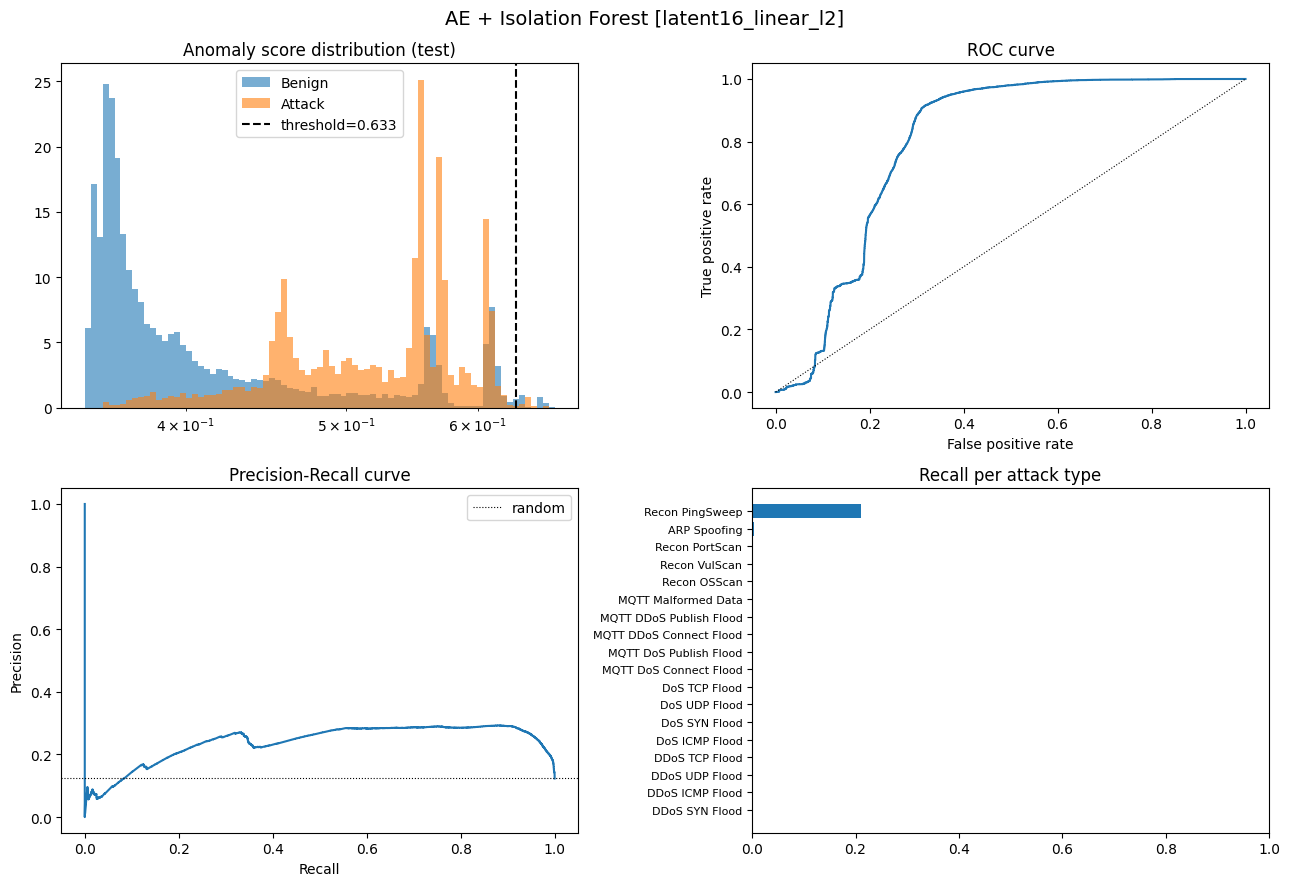


Saved to /content/iomt-anomaly-detection/results/results.csv

===== AE Reconstruction [latent16_linear_l2] =====
Threshold (P99 of validation scores): 0.0021731
          roc_auc: 0.9616
           pr_auc: 0.9048
               f1: 0.8747
        precision: 0.9305
           recall: 0.8252
 false_alarm_rate: 0.0087

Confusion matrix (rows = true, cols = predicted)
        Benign  Attack
Benign   37281     326
Attack     924    4362

Recall per attack type (weakest first):
                           n recall
type                               
ARP Spoofing             300  0.027
MQTT Malformed Data      300  0.257
Recon VulScan            300  0.483
Recon PingSweep          186  0.489
MQTT DoS Publish Flood   300  0.720
Recon OSScan             300  0.880
MQTT DDoS Publish Flood  300  0.903
Recon PortScan           300  0.970
DoS ICMP Flood           300  0.997
DoS SYN Flood            300  1.000
DDoS SYN Flood           300  1.000
MQTT DDoS Connect Flood  300  1.000
DDoS UDP Flood    

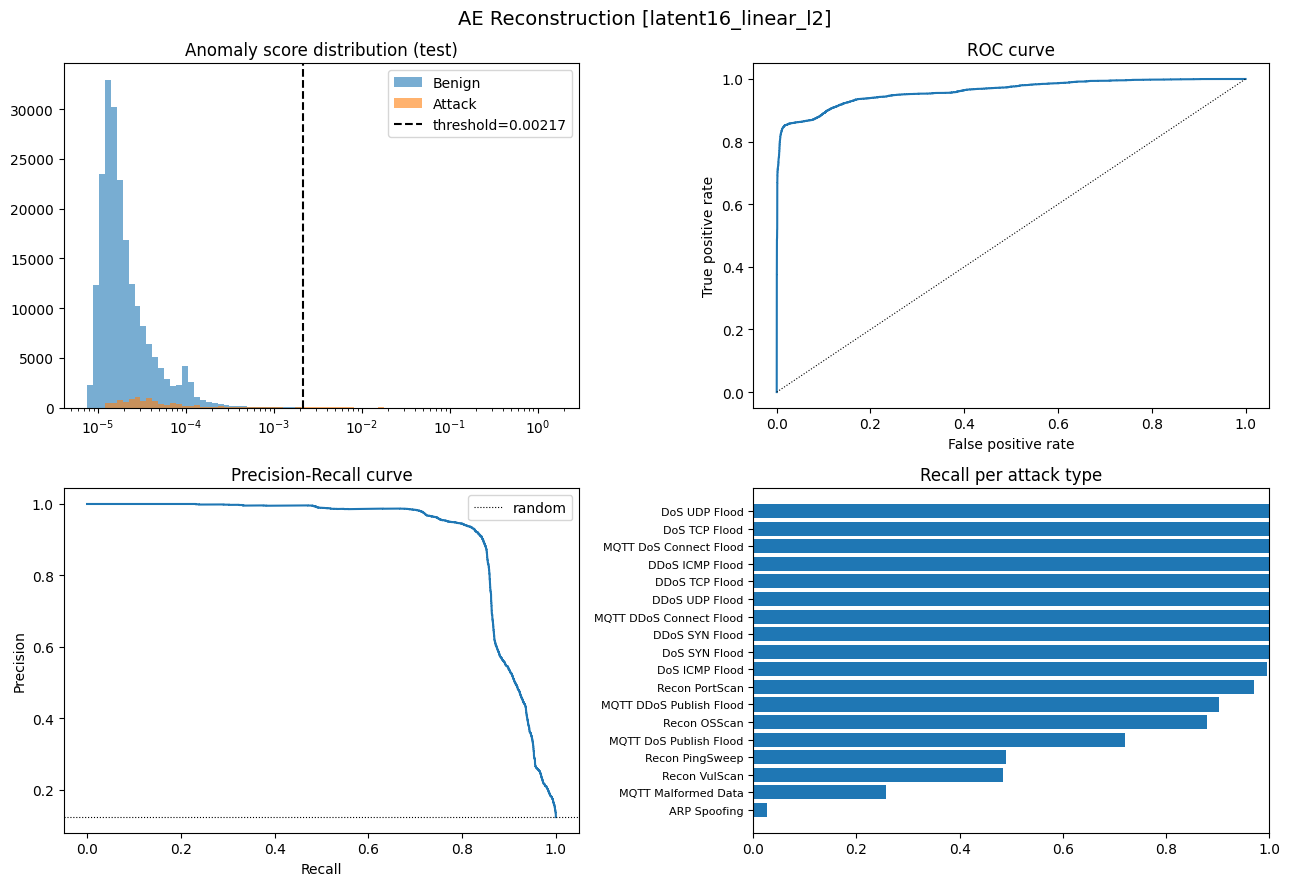


Saved to /content/iomt-anomaly-detection/results/results.csv


,method,F1,PR-AUC,ROC-AUC
0,AE + Isolation Forest,0.013493,0.239899,0.798251
1,AE reconstruction error,0.874674,0.904751,0.961580
2,PCA baseline (project reference),0.761000,0.835000,0.938000


In [ ]:
test_scores = iso_scores(X_test)
iso_res = evaluate(test_scores, y_test, attack_test, val_scores,
                   model_name=f'AE + Isolation Forest [{EXPERIMENT}]', person='4', save_dir=RESULTS_DIR)
ae_test_scores = reconstruction_errors(autoencoder, X_test)
ae_res = evaluate(ae_test_scores, y_test, attack_test, ae_val_scores,
                  model_name=f'AE Reconstruction [{EXPERIMENT}]', person='4', save_dir=RESULTS_DIR)
comparison = pd.DataFrame([
    {'method':'AE + Isolation Forest', 'F1':iso_res.get('f1'), 'PR-AUC':iso_res.get('pr_auc'), 'ROC-AUC':iso_res.get('roc_auc')},
    {'method':'AE reconstruction error', 'F1':ae_res.get('f1'), 'PR-AUC':ae_res.get('pr_auc'), 'ROC-AUC':ae_res.get('roc_auc')},
    {'method':'PCA baseline (project reference)', 'F1':0.761, 'PR-AUC':0.835, 'ROC-AUC':0.938}])
display(comparison)

## 8 — Save both models and verify exact score consistency



In [ ]:
OUTPUT_DIR = REPO / 'models' / 'ae_isoforest' / EXPERIMENT
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
autoencoder.save(str(OUTPUT_DIR / 'ae_isoforest.keras'))
joblib.dump(iso, OUTPUT_DIR / 'isolation_forest.pkl')
metadata = {'experiment':EXPERIMENT, 'threshold':float(iso_res['threshold']),
            'latent_size':LATENT_SIZE, 'latent_activation':LATENT_ACTIVATION,
            'l2_strength':L2_STRENGTH, 'n_estimators':N_ESTIMATORS,
            'max_samples':MAX_SAMPLES, 'seed':SEED}
with open(OUTPUT_DIR / 'metadata.json', 'w') as f: json.dump(metadata, f, indent=2)
loaded_ae = keras.models.load_model(str(OUTPUT_DIR / 'ae_isoforest.keras'))
loaded_iso = joblib.load(OUTPUT_DIR / 'isolation_forest.pkl')
loaded_encoder = keras.Model(loaded_ae.inputs, loaded_ae.get_layer('latent').output)
loaded_scores = -loaded_iso.score_samples(loaded_encoder.predict(X_test, verbose=0))
np.testing.assert_allclose(loaded_scores, test_scores, atol=1e-6, rtol=1e-6)
print('Save/load verification PASSED:', OUTPUT_DIR)

Save/load verification PASSED: /content/iomt-anomaly-detection/models/ae_isoforest/latent16_linear_l2


## 9 — Predict new rows



In [ ]:
with open(Path(DATA_DIR) / 'config.json') as f:
    FEATURES = json.load(f)['features']
THRESHOLD = float(iso_res['threshold'])
def predict(X):
    X = np.asarray(X)
    if X.ndim == 1: X = X.reshape(1, -1)
    if X.ndim != 2 or X.shape[1] != 40:
        raise ValueError('Expected shape (n_rows, 40) with preprocessed features')
    scores = iso_scores(X)
    errors = per_feature_errors(autoencoder, X)
    top = [[FEATURES[j] for j in np.argsort(-row)[:3]] for row in errors]
    return [{'score':float(s), 'is_anomaly':bool(s > THRESHOLD), 'top_features':names}
            for s,names in zip(scores,top)]
display(pd.DataFrame(predict(X_test[:5])))

,score,is_anomaly,top_features
0,0.357751,False,"[max, duration, avg]"
1,0.556047,False,"[ack_flag_number, tcp, udp]"
2,0.428954,False,"[max, tot_size, magnitue]"
3,0.465305,False,"[syn_flag_number, number, iat]"
4,0.363122,False,"[radius, avg, min]"
